# Cropland Area Dynamics in Western Kansas from MODIS Land Cover (2001–2023)

This notebook quantifies annual cropland area within a region of interest (ROI) using the
**MODIS MCD12Q1 v6.1** land cover product (IGBP scheme, `LC_Type1`, 500 m) in Google Earth Engine.

Cropland is defined as IGBP classes:

| Class | Description |
|---|---|
| 12 | Croplands |
| 14 | Cropland / Natural Vegetation Mosaics |

**Outputs:** annual area table (CSV), trend statistics (OLS, Theil–Sen, Mann–Kendall), time-series figures,
and spatial maps of cropland in the first and last year plus a gain/loss map.

> Ported from the original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

In [5]:
# Uncomment on first run
# %pip install earthengine-api pandas matplotlib scipy requests pillow
%pip install earthengine-api numpy pandas matplotlib requests pillow scipy

   ---------------------------------------- 0.0/484.8 kB ? eta -:--:--
   ------------- -------------------------- 163.8/484.8 kB 5.0 MB/s eta 0:00:01
   ---------------------------------------  481.3/484.8 kB 5.0 MB/s eta 0:00:01
   ---------------------------------------- 484.8/484.8 kB 4.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/16.8 MB ? eta -:--:--
    --------------------------------------- 0.3/16.8 MB 10.6 MB/s eta 0:00:02
   -- ------------------------------------- 0.9/16.8 MB 9.9 MB/s eta 0:00:02
   --- ------------------------------------ 1.5/16.8 MB 10.5 MB/s eta 0:00:02
   ---- ----------------------------------- 1.9/16.8 MB 9.9 MB/s eta 0:00:02
   ---- ----------------------------------- 1.9/16.8 MB 9.1 MB/s eta 0:00:02
   ----- ---------------------------------- 2.2/16.8 MB 7.7 MB/s eta 0:00:02
   ----- ---------------------------------- 2.2/16.8 MB 7.8 MB/s eta 0:00:02
   ----- ---------------------------------- 2.4/16.8 MB 6.7 MB/s eta 0:00:03
 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
conda-repo-cli 1.0.75 requires requests_mock, which is not installed.
conda-repo-cli 1.0.75 requires clyent==1.2.1, but you have clyent 1.2.2 which is incompatible.
conda-repo-cli 1.0.75 requires requests==2.31.0, but you have requests 2.34.2 which is incompatible.
streamlit 1.30.0 requires protobuf<5,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [10]:

import ee

# Authenticate your Google Earth Engine account
ee.Authenticate(auth_mode="localhost")

# Initialize Earth Engine with your Google Cloud project
ee.Initialize(project="YOUR GEE USERNAME")

print("Google Earth Engine initialized successfully!")



Successfully saved authorization token.
Google Earth Engine initialized successfully!


In [14]:
import os, io
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import requests
from PIL import Image
from scipy import stats


os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

## 2. Parameters

The study area is the western part of Kansas, cut from the state boundary at a chosen meridian. In the GEE Code Editor you can run `print(geometry)` and copy
the coordinates, or upload a shapefile as an asset and load it with `ee.FeatureCollection("users/...")`.

In [15]:
# --- Region of interest: Western Kansas ---
# Kansas boundary from US Census TIGER, cut at a meridian to keep the western part.
WEST_OF_LON = -99.0   # Kansas spans ~-102.05 to -94.59; use -100.0 for west of the 100th meridian

kansas = (ee.FeatureCollection("TIGER/2018/States")
            .filter(ee.Filter.eq("NAME", "Kansas"))
            .geometry())
west_box = ee.Geometry.Rectangle([-103.0, 36.0, WEST_OF_LON, 41.0])
roi = kansas.intersection(west_box, ee.ErrorMargin(100))

# Alternative: build the ROI from a list of counties instead of a meridian
# WEST_COUNTIES = ["Finney", "Ford", "Gray", "Haskell", "Seward"]   # edit as needed
# roi = (ee.FeatureCollection("TIGER/2018/Counties")
#          .filter(ee.Filter.eq("STATEFP", "20"))
#          .filter(ee.Filter.inList("NAME", WEST_COUNTIES))
#          .geometry())

ROI_NAME   = "Western Kansas"
START_YEAR = 2001
END_YEAR   = 2023          # MCD12Q1 annual maps; extend if newer years are available
SCALE      = 500           # native MODIS resolution (m)
CROP_CLASSES = {12: "Croplands", 14: "Cropland/Natural Vegetation Mosaic"}

print(f"ROI area: {roi.area(100).divide(1e6).getInfo():,.0f} km²")

ROI area: 88,501 km²


## 3. Load MODIS land cover

In [16]:
modis = (ee.ImageCollection("MODIS/061/MCD12Q1")
         .select("LC_Type1")
         .filterDate(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31")
         .sort("system:time_start"))

print("Images in collection:", modis.size().getInfo())

Images in collection: 23


## 4. Annual cropland area per class

Equivalent to the original `cropland_area()` function + `ui.Chart.image.series(..., ee.Reducer.sum(), 500)`,
but split by class and with the ROI area added so we can compute cropland share.

In [17]:
def cropland_stats(img):
    lc = img.select("LC_Type1")
    px_km2 = ee.Image.pixelArea().divide(1e6)
    bands = ee.Image.cat(
        lc.eq(12).multiply(px_km2).rename("croplands_km2"),
        lc.eq(14).multiply(px_km2).rename("mosaic_km2"),
        lc.eq(12).Or(lc.eq(14)).multiply(px_km2).rename("total_km2"),
        px_km2.rename("roi_km2"),
    )
    s = bands.reduceRegion(reducer=ee.Reducer.sum(), geometry=roi,
                           scale=SCALE, maxPixels=1e13, tileScale=4)
    return ee.Feature(None, s).set("year", img.date().get("year"))

fc = modis.map(cropland_stats)
rows = [f["properties"] for f in fc.getInfo()["features"]]

df = (pd.DataFrame(rows)
        .astype({"year": int})
        .set_index("year")
        .sort_index()[["croplands_km2", "mosaic_km2", "total_km2", "roi_km2"]])
df["share_pct"] = 100 * df["total_km2"] / df["roi_km2"]
df["yoy_change_km2"] = df["total_km2"].diff()
df.round(2).to_csv("outputs/cropland_area_annual.csv")
df.round(2)

,croplands_km2,mosaic_km2,total_km2,roi_km2,share_pct,yoy_change_km2
year,,,,,,
2001,36899.07,3.67,36902.75,88604.29,41.65,NaN
2002,28175.17,0.00,28175.17,88604.29,31.80,-8727.58
2003,30992.81,0.00,30992.81,88604.29,34.98,2817.64
2004,33615.38,0.00,33615.38,88604.29,37.94,2622.57
2005,34724.20,0.00,34724.20,88604.29,39.19,1108.82
2006,31653.64,0.00,31653.64,88604.29,35.72,-3070.56
2007,36820.94,0.00,36820.94,88604.29,41.56,5167.29
2008,33499.12,0.00,33499.12,88604.29,37.81,-3321.81
2009,32874.81,0.25,32875.06,88604.29,37.10,-624.07


## 5. Summary and trend statistics

In [18]:
years = df.index.values
y = df["total_km2"].values

ols = stats.linregress(years, y)
ts_slope, ts_int, ts_lo, ts_hi = stats.theilslopes(y, years)
tau, mk_p = stats.kendalltau(years, y)    # Mann-Kendall test (no ties in years)

first, last = df.iloc[0], df.iloc[-1]
summary = pd.Series({
    "Period": f"{years[0]}–{years[-1]}",
    "Cropland area, first year (km²)": first.total_km2,
    "Cropland area, last year (km²)": last.total_km2,
    "Net change (km²)": last.total_km2 - first.total_km2,
    "Relative change (%)": 100 * (last.total_km2 / first.total_km2 - 1),
    "Mean area (km²)": y.mean(),
    "Std. dev. (km²)": y.std(ddof=1),
    "Coefficient of variation (%)": 100 * y.std(ddof=1) / y.mean(),
    "Max year": int(df.total_km2.idxmax()),
    "Min year": int(df.total_km2.idxmin()),
    "OLS slope (km²/yr)": ols.slope,
    "OLS R²": ols.rvalue ** 2,
    "OLS p-value": ols.pvalue,
    "Theil–Sen slope (km²/yr)": ts_slope,
    "Theil–Sen 95% CI": f"[{ts_lo:.2f}, {ts_hi:.2f}]",
    "Mann–Kendall tau": tau,
    "Mann–Kendall p-value": mk_p,
}, name="value")
summary.to_csv("outputs/cropland_trend_summary.csv")
summary.to_frame().style.format(lambda v: f"{v:,.3f}" if isinstance(v, float) else v)

,value
Period,2001–2023
"Cropland area, first year (km²)","36,902.746"
"Cropland area, last year (km²)","38,565.474"
Net change (km²),"1,662.728"
Relative change (%),4.506
Mean area (km²),"33,143.931"
Std. dev. (km²),"3,103.203"
Coefficient of variation (%),9.363
Max year,2023
Min year,2011


## 6. Figures

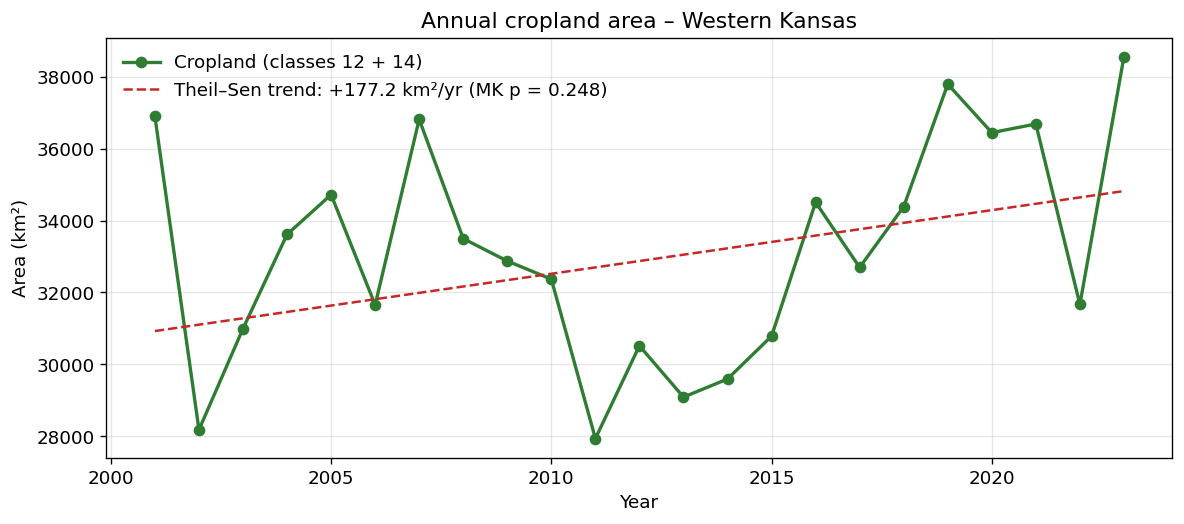

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(years, y, "o-", color="#2e7d32", lw=2, label="Cropland (classes 12 + 14)")
ax.plot(years, ts_int + ts_slope * years, "--", color="#c62828",
        label=f"Theil–Sen trend: {ts_slope:+.1f} km²/yr (MK p = {mk_p:.3f})")
ax.set(xlabel="Year", ylabel="Area (km²)", title=f"Annual cropland area – {ROI_NAME}")
ax.grid(alpha=0.3); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/01_cropland_timeseries.png"); plt.show()

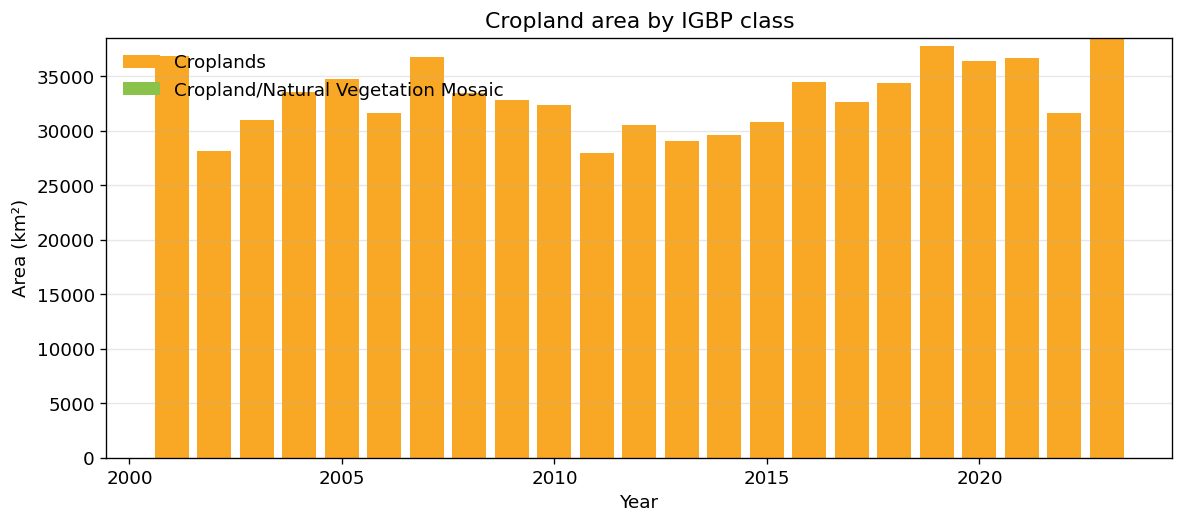

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(years, df["croplands_km2"], color="#f9a825", label=CROP_CLASSES[12])
ax.bar(years, df["mosaic_km2"], bottom=df["croplands_km2"], color="#8bc34a", label=CROP_CLASSES[14])
ax.set(xlabel="Year", ylabel="Area (km²)", title="Cropland area by IGBP class")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("figures/02_cropland_by_class.png"); plt.show()

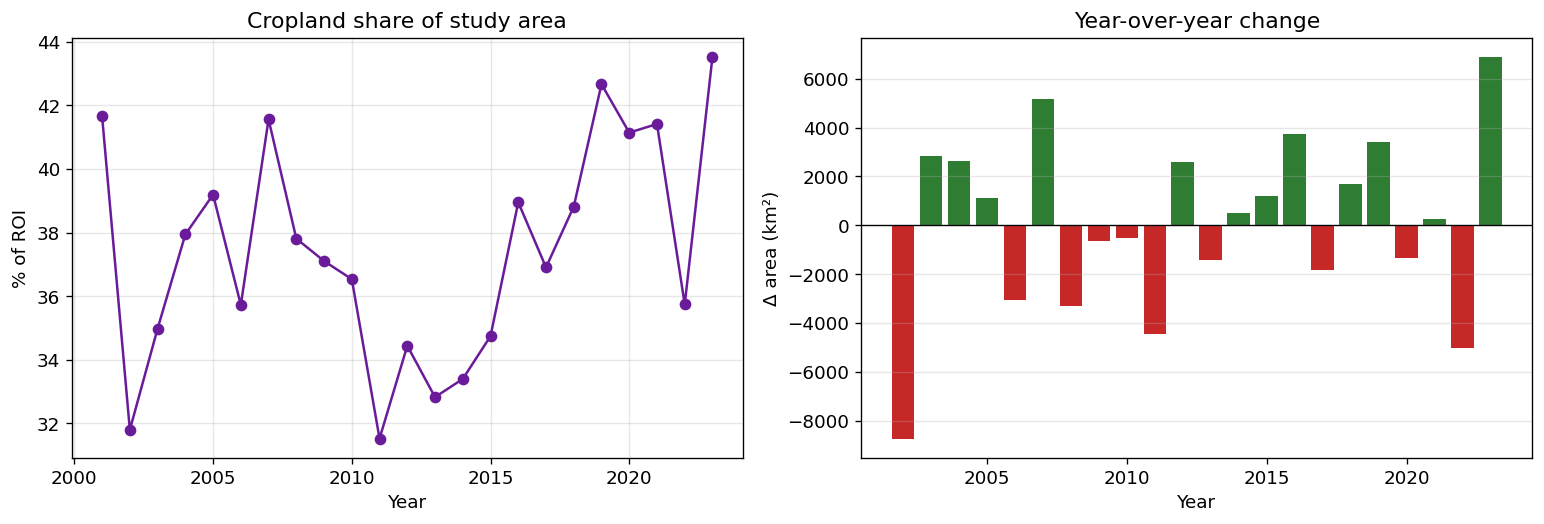

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(years, df["share_pct"], "o-", color="#6a1b9a")
ax1.set(xlabel="Year", ylabel="% of ROI", title="Cropland share of study area"); ax1.grid(alpha=0.3)

yoy = df["yoy_change_km2"].dropna()
ax2.bar(yoy.index, yoy.values, color=np.where(yoy.values >= 0, "#2e7d32", "#c62828"))
ax2.axhline(0, color="k", lw=0.8)
ax2.set(xlabel="Year", ylabel="Δ area (km²)", title="Year-over-year change"); ax2.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("figures/03_share_and_yoy.png"); plt.show()

## 7. Spatial maps

Maps are rendered as static images (via `getThumbURL`) so they display directly on GitHub,
unlike interactive map widgets.

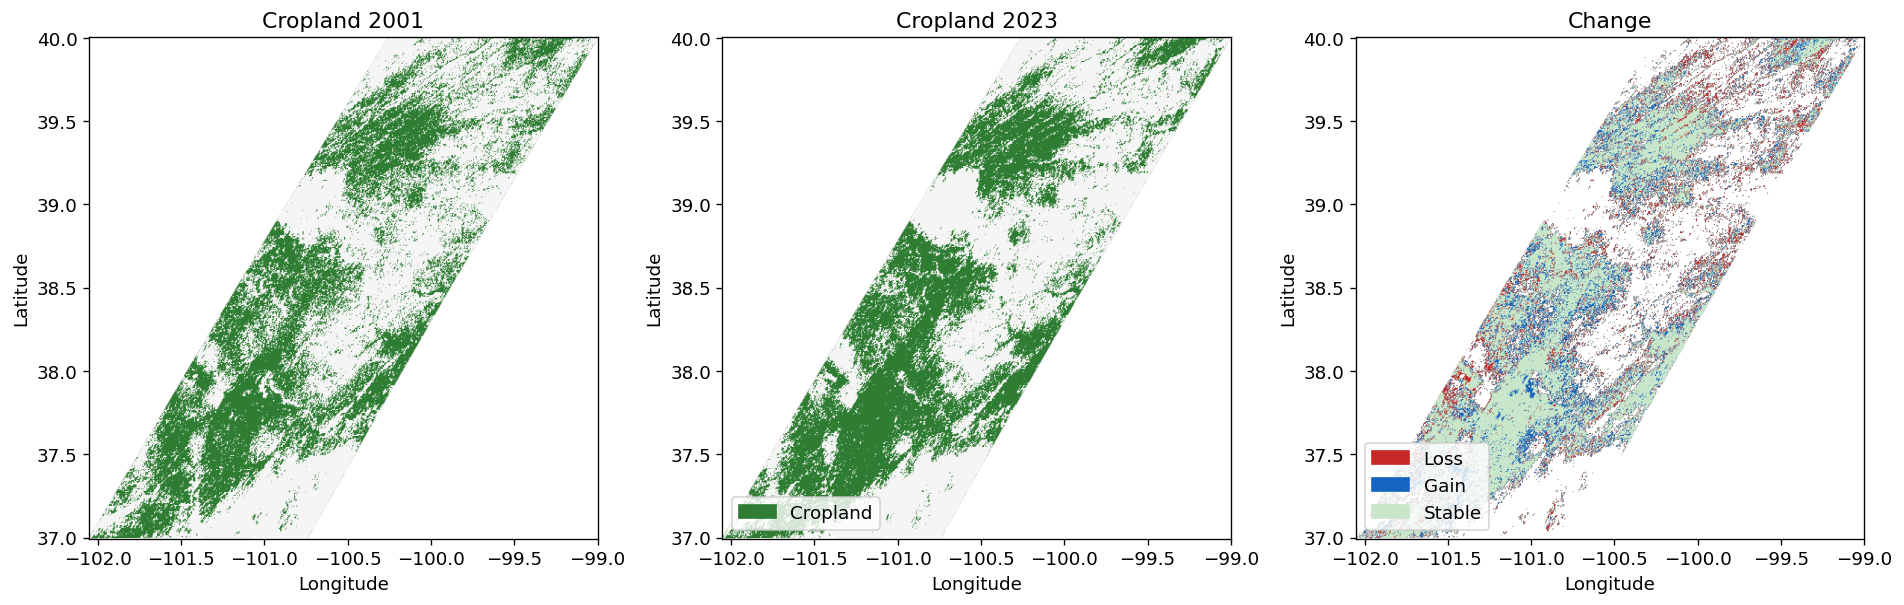

In [23]:
def ee_to_array(image, vis, dim=1024):
    url = image.getThumbURL({**vis, "region": roi, "dimensions": dim, "format": "png"})
    return np.array(Image.open(io.BytesIO(requests.get(url, timeout=120).content)))

def is_crop(img):
    lc = img.select("LC_Type1")
    return lc.eq(12).Or(lc.eq(14))

img_first = modis.first()
img_last  = modis.sort("system:time_start", False).first()
crop_first, crop_last = is_crop(img_first), is_crop(img_last)

# 1 = loss, 2 = gain, 3 = stable cropland
change = crop_first.add(crop_last.multiply(2))
change = change.updateMask(change.gt(0)).clip(roi)

bounds = np.array(roi.bounds().coordinates().getInfo()[0])
extent = [bounds[:, 0].min(), bounds[:, 0].max(), bounds[:, 1].min(), bounds[:, 1].max()]

crop_vis = {"min": 0, "max": 1, "palette": ["f5f5f5", "2e7d32"]}
maps = {
    f"Cropland {START_YEAR}": ee_to_array(crop_first.clip(roi), crop_vis),
    f"Cropland {END_YEAR}":   ee_to_array(crop_last.clip(roi), crop_vis),
    "Change": ee_to_array(change, {"min": 1, "max": 3, "palette": ["c62828", "1565c0", "c8e6c9"]}),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (title, arr) in zip(axes, maps.items()):
    ax.imshow(arr, extent=extent)
    ax.set_title(title); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
axes[1].legend(handles=[mpatches.Patch(color="#2e7d32", label="Cropland")], loc="lower left")
axes[2].legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
                        [("#c62828", "Loss"), ("#1565c0", "Gain"), ("#c8e6c9", "Stable")]],
               loc="lower left")
fig.tight_layout(); fig.savefig("figures/04_cropland_maps.png"); plt.show()

In [ ]:
# Gain / loss / stable area statistics
px = ee.Image.pixelArea().divide(1e6)
chg_area = ee.Image.cat(
    change.eq(1).multiply(px).rename("loss_km2"),
    change.eq(2).multiply(px).rename("gain_km2"),
    change.eq(3).multiply(px).rename("stable_km2"),
).reduceRegion(ee.Reducer.sum(), roi, SCALE, maxPixels=1e13, tileScale=4).getInfo()

chg = pd.Series(chg_area).round(2)
chg["net_km2"] = round(chg["gain_km2"] - chg["loss_km2"], 2)
chg.to_csv("outputs/cropland_change_first_last.csv")
chg

## 8. Notes

- **Data:** Friedl, M., Sulla-Menashe, D. (2022). *MODIS/Terra+Aqua Land Cover Type Yearly L3 Global 500m SIN Grid V061*. NASA EOSDIS LP DAAC.
- Area is computed with `ee.Image.pixelArea()` at 500 m, so values are approximate; mixed pixels at the ROI boundary are weighted by coverage.
- The Mann–Kendall test is implemented via Kendall's tau between year and area; serial autocorrelation is not corrected for.
- Class 14 is a mosaic class, so it includes natural vegetation; interpret it as an upper bound of cropland extent.